# 1. Introduction

The **One-dimensional heat diffusion in a semi-infinite rod** problem consists of measuring the temperature variation over time of a semi-infinite rod. The temperature time history is measured at a distance $x_{\text{m}}$ from the origin (at $x = 0$), $T(x_{\text{m}},t)$. The task is to recover the time history at the origin, $T(0,t)$, which may be difficult to access or too hot to do so. See Figure 1 for a problem schematic.

<figure style="text-align: center;">
    <img src="figures\bar_temp.svg" width="700" alt="One-dimensional heat diffusion conceptual image.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figure 1: Schematics of one-dimensional heat diffusion in a semi-infinite rod problem.
    </figcaption>
</figure>

# 2. Basic theory

Consider a homogeneous rod occupying the region $x \geq 0$ with constant thermal diffusivity $\alpha$. Assuming one-dimensional heat conduction, the temperature satisfies:

\begin{equation}
    \frac{\partial T(x,t)}{\partial t}
    =
    \alpha\frac{\partial^2 T(x,t)}{\partial x^2},
    \qquad x>0,\quad t>0.
\tag{1}
\end{equation}

The rod is initially at a known uniform temperature $T(x,0)= T_0$ for $ x>0$. The boundary temperature is an unknown function $T(0,t)=T_s(t), t>0$. Far from the boundary, the temperature approaches its initial value: $\lim\limits_{x\to\infty}T(x,t)=T_0$. Measurements are taken at a fixed position $x_{\text{m}}>0$. The inverse problem consists of reconstructing the boundary-temperature history $T_s(t)$ from the measured temperature $T(x_{\text{m}},t)$.

For a general boundary-temperature history, define the temperature rise:

\begin{equation}
    u(t)=T_s(t)-T_0,
\tag{2}
\end{equation}

and

\begin{equation}
     y(t)=T(x_{\text{m}},t)-T_0.
\tag{3}
\end{equation}

The forward problem is expressed as a causal convolution:

\begin{equation}
    y(t) = \int_0^t K(x_{\text{m}},t-s)u(s)\,ds,
\tag{4}
\end{equation}

where the heat kernel is

\begin{equation}
    K(x_m,\tau) = \frac{x_{\text{m}}}{2\sqrt{\pi\alpha}\,\tau^{3/2}}
    \exp\left(-\frac{x_{\text{m}}^2}{4\alpha\tau}\right),
    \qquad \tau>0.
\tag{5}
\end{equation}

The kernel vanishes for $\tau \leq 0$.

## 2.1. Time discretization

Let the measurement times be $t_i = i\Delta t$, for $i=0,\ldots,N-1$. Here $\Delta t = 1/f_s$ [s] is the sampling interval and $f_s$ is the sampling frequency.

The boundary-temperature rise is approximated by a constant $u_j$ over each interval $[t_j,t_{j+1})$, for $j=0,\ldots,N-2$. Consequently, there are $N$ measurement instants but only $N-1$ unknown source values.

## 2.2. Integrated kernel weights

The cumulative integral of the heat kernel is

\begin{equation}
    F(\tau) = \operatorname{erfc}\left(
        \frac{x_m}{2\sqrt{\alpha\tau}}
    \right), \qquad \tau>0,
\tag{6}
\end{equation}

with $F(0)=0$. The exact kernel weights are

\begin{equation}
    w_k = F((k+1)\Delta t)-F(k\Delta t),
    \qquad k=0,\ldots,N-2.
\tag{7}
\end{equation}

Integrating the kernel over each interval avoids the errors associated with evaluating a sharply peaked kernel at isolated time lags.

## 2.3. Sensing matrix

The discrete forward model is

\begin{equation}
    \mathbf{y}_{\mathrm{true}} = \mathbf{A}\mathbf{u}_{\mathrm{true}},
\tag{8}
\end{equation}

where

\begin{equation}
    \mathbf{u}_{\mathrm{true}} = \mathbf{x}_{\mathrm{true}}-T_0\mathbf{1},
\tag{9}
\end{equation}

and

\begin{equation}
    \mathbf{y}_{\mathrm{true}} = \mathbf{b}_{\mathrm{true}}-T_0\mathbf{1}.
\tag{10}
\end{equation}

The matrix entries are

\begin{equation}
    A_{ij} =
    \begin{cases}
    w_{i-j-1}, & i>j,\\
    0, & i\leq j,
    \end{cases}
\tag{11}
\end{equation}

for $i=0,\ldots,N-1$ and $j=0,\ldots,N-2$.

Thus,

\begin{equation}
    \mathbf{A}
    =
    \begin{bmatrix}
    0   & 0   & 0   & \cdots & 0 \\
    w_0 & 0   & 0   & \cdots & 0 \\
    w_1 & w_0 & 0   & \cdots & 0 \\
    w_2 & w_1 & w_0 & \cdots & 0 \\
    \vdots & \vdots & \vdots & \ddots & \vdots
    \end{bmatrix}
    \in \mathbb{R}^{N\times(N-1)}.
\tag{12}
\end{equation}

The matrix is **lower-triangular** in the rectangular sense and has a Toeplitz structure: its entries are constant along each diagonal.

`PyRegTools` provides a way to set up the `TempSemiInfRod` via the `toyproblems` module. With this class, you can provide information about your simulated measurement ($e.g.$ $x_{\text{m}}$, $\alpha$, $T_0$, $f_s$, $t_{\text{max}}$ - the latter being the maximum measurement time instant). You can also form the sensing matrix, compute several source terms, compute the forward problem, and add noise. Let's investigate this problem and its inverse counterpart.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyregtools
from pyregtools.toyproblems.temp_semi_inf_rod import TempSemiInfRod
from pyregtools import regsolvers
from pyregtools import iterativesolvers
from pyregtools import regchoice

In [2]:
def plot_measurement(problem, x_sol = None, nmse = 0, source_lim = (0, 250), b_lim = (80, 200)):
    """ Helping function to do specific plots of source terms and measured signals.
    """
    fig, axs = plt.subplots(1, 2, figsize = (9,3))
    axs[0].plot(problem.time[1:], problem.x_true, '--k', label = 'True source')
    if x_sol is not None:
        axs[0].plot(problem.time[1:], x_sol, 'royalblue', alpha = 0.8, label = r'Est. sol. (NMSE = {:.2e})'.format(nmse))
    axs[0].legend()
    axs[0].grid(linestyle = '--')
    axs[0].set_xlim((0, problem.time[-1]+1/problem.fs))
    axs[0].set_ylim((source_lim[0],source_lim[1]))
    axs[0].set_xlabel(r'time [s]')
    axs[0].set_ylabel(r'$T(t)$  [K]')
    axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = {:.2e}$)'.format(np.linalg.cond(problem.A)))
    axs[1].plot(problem.time, problem.b_true, '--k', label = r'True meas.')
    if hasattr(problem, "b_noisy"):
        axs[1].plot(problem.time, problem.b_noisy, label = r'Noisy measurement', color = 'royalblue', alpha = 0.8)
    axs[1].grid(linestyle = '--')
    axs[1].set_xlim((0, problem.time[-1]+1/problem.fs))
    axs[1].set_ylim(b_lim)
    axs[1].legend()
    axs[1].set_xlabel(r'time [s]')
    axs[1].set_ylabel(r'$T(t)$  [K]')
    axs[1].set_title(r'Measured temperature ($x_m = {}$ m)'.format(problem.xm))
    plt.tight_layout()

# Forward problem

Let's instantiate the `TempSemiInfRod` and compute the pre-sensing matrix. The matrix will be stored at `problem.A`. We will also choose a given signal-to-noise ratio (SNR) to add noise later.

In [3]:
problem = TempSemiInfRod(xm=1.0, alpha = 1.0, T0 = 100, tmax = 10, fs = 20) # instantiate the problem
problem.sens_mtx() # build the sensing matrix
print("Shape of A: {}".format(problem.A.shape))
snr = 30 # Your desired SNR

Shape of A: (200, 199)


# 3. Available source terms

`TempSemiInfRod` provides different source terms to play with. Evoking each of them creates the `problem.b_true` (our noiseless measurement).

# 3.1. Step of temperature

The first one we will investigate is `temp_step`, which generates a step in the boundary-temperature history. In other words, the boundary temperature changes from the initial temperature $T_0$ to $T_{\mathrm{source}}$ at the specified time, $t_s$, as in the following equation: 

\begin{equation}
    T_s(t) =
    \begin{cases}
    T_0, & t<t_s,\\
    T_{\mathrm{source}}, & t\geq t_s,
    \end{cases}
\end{equation}

`TempSemiInfRod` also provides the method `temp_analytical_step`, which independently implements the analytical solution for such a source term. Then the curious reader can use the method to compare `b_analytical` with `b_true`.

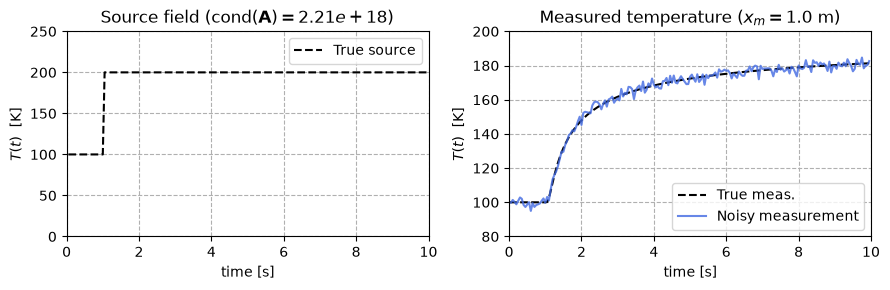

In [4]:
problem.temp_step(time_step=1.0, T_source=200.0)
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

# 3.2. Square pulse of temperature

The method `temp_square_pulse` provides a source function that is a square pulse in the boundary-temperature history. The boundary temperature equals $T_{\mathrm{source}}$ during a specified time interval and $T_0$ elsewhere. In mathematical terms,

\begin{equation}
    T_s(t) =
    \begin{cases}
    T_{\mathrm{source}},
    & t_{\mathrm{init}}<t<t_{\mathrm{end}},\\
    T_0, & \text{otherwise}.
    \end{cases}
\end{equation}

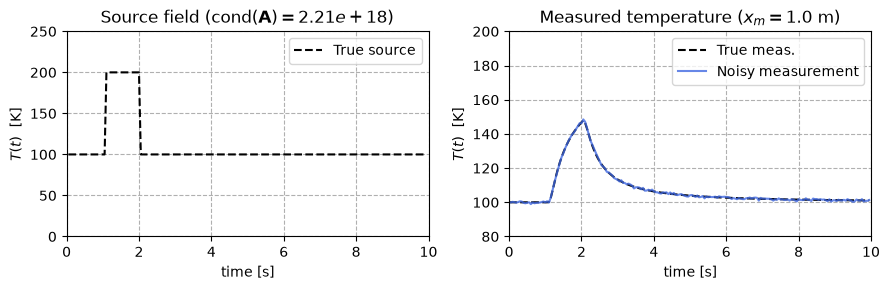

In [5]:
problem.temp_square_pulse(time_init=1, time_end=2, T_source=200) # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

# 3.3. Random fluctuations of temperature

The method `temp_random` provides a source function that generates a random boundary-temperature history. The boundary temperature is independently sampled from a normal distribution over each source interval, as in

\begin{equation}
T_{s,j} \sim \mathcal{N}(T_0,\sigma_T^2),
\end{equation}

where $\sigma_T^2$ is **variance** of the normal distribution.

Such a signal has an expected spectrum that is flat (i.e., energy is uniformly distributed across all frequencies). Note how the source term varies quite a lot because of this effect. Note also how the measured signal varies much less. The reason is the attenuation of high frequencies at the measurement position.

The curious reader can also examine how the measured signals change as the measurement distance varies. For instance, this was done in the [Gravity Survey notebook](gravity_survey.ipynb). 

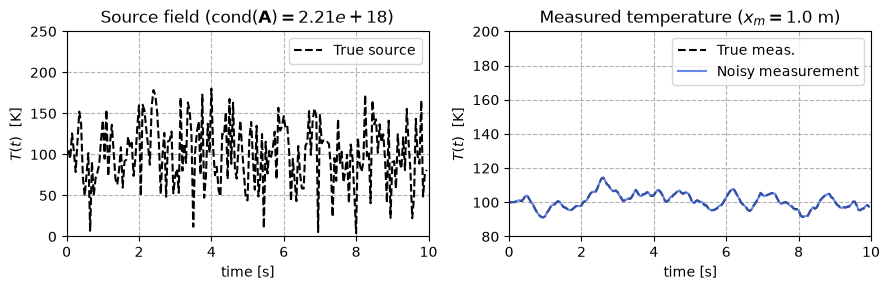

In [6]:
problem.temp_random(std_temp=40.0, seed=0)
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

# 3.4. Hanning pulse of temperature

The method `temp_hann_pulse` provides a source function that generates a Hann-shaped boundary-temperature pulse. The boundary temperature varies smoothly from $T_0$ toward $T_{\mathrm{source}}$ and returns $T_0$. 

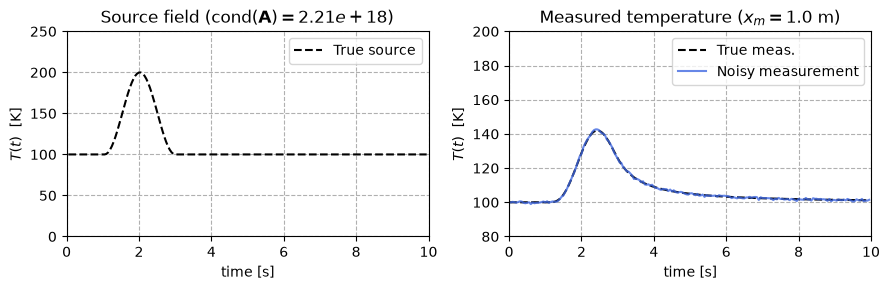

In [7]:
problem.temp_hann_pulse(time_init=1.0, time_end=3.0, T_source=200.0) # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

# 4. Inverse problem via the naive solution

Let's formulate the inverse problem for `TempSemiInfRod`. 

The first row of $\mathbf{A}$ is zero because the measurement at $t=0$ equals the known initial temperature $T_0$ and contains no information about the boundary temperature history. For inversion, the first row and the corresponding measurement are removed, resulting in:

\begin{equation}
    \mathbf{A}^{\prime} = \mathbf{A}[1:,:]
\tag{13}
\end{equation}

\begin{equation}
\mathbf{y} = \mathbf{b}[1:]-T_0\mathbf{1}.
\tag{14}
\end{equation}

Note that it is necessary to remove $T_0$ from the measurement vector, because what we estimate is the temperature rise (see Eqs. (2-4)) and not the temperature itself. We can either assume that $T_0$ is known or estimate it by taking the mean value of the noisy signal between 0 and 1 [s] (the time instant at which it changes for most source terms).

The resulting system of equations is

\begin{equation}
    \mathbf{A}^{\prime}\mathbf{u} = \mathbf{y},
\tag{15}
\end{equation}
where $\mathbf{A}^{\prime} \in \mathbb{R}^{N-1 \times N-1}$, and $N$ is the number of measured samples in time. 


As with the [Gravity Survey notebook](gravity_survey.ipynb), let’s see what happens with the **naive** solution, given by 

\begin{equation}
\mathbf{u} = (\mathbf{A}^{\prime})^{\dagger}\mathbf{y} = \mathbf{V} \boldsymbol{\Sigma}^{-1} \mathbf{U}^H \mathbf{b},
\tag{16}
\end{equation}
where we will use the SVD of $\mathbf{A}^{\prime}$ for numerical reasons ($\mathbf{A}^{\prime} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^H$).

After estimating the boundary-temperature rise $\mathbf{u}$, the absolute boundary temperature is recovered as 

\begin{equation}
    \mathbf{x} = \mathbf{u}+T_0\mathbf{1}.
\tag{17}
\end{equation}

You’ll see that the naive solution is useless, and we need to find a **regularized** solution.

Baseline temperature is 99.9185


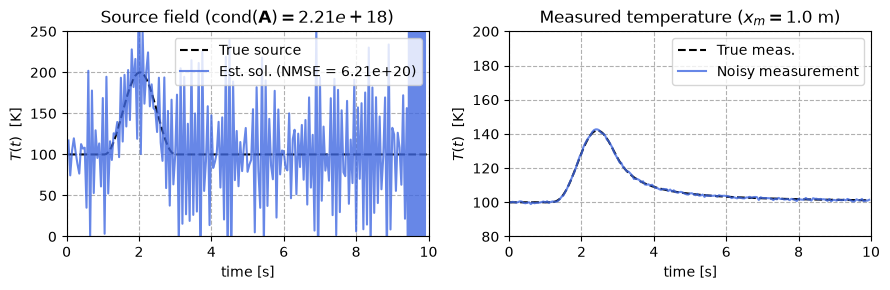

In [8]:
base_temp = np.mean(problem.b_noisy[problem.time<1.0])
print("Baseline temperature is {:.4f}".format(base_temp))

# removing the biases
A = problem.A[1:, :]
y = problem.b_noisy[1:]-base_temp

# Let's use the SVD as the usual inv is even worse
u, s, v = regsolvers.csvd(A)
us = (v @ np.diag(1/s) @ np.conj(u).T) @ y
x_naive = us + base_temp
nmse_naive = pyregtools.utils.nmse_fun(x_meas = x_naive, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_naive, nmse = nmse_naive)

# 5. SVD basis and the Picard plot

In the [Gravity Survey notebook](gravity_survey.ipynb), we studied in detail why the naive solution fails. The reader can also consult the notebook; there is no need to repeat the theory here. Let's plot the column vectors of the matrix $\mathbf{U}$ for this problem. You will notice that as the index increases, the corresponding column vector oscillates more and more rapidly. This means that the smaller singular values, $\sigma$, correspond to higher frequencies in the measured signal (including the noise projection of $\mathbf{b}$ onto $\mathbf{U}$). Let's also analyze the Picard plot of this problem and notice that it can be challenging to recover the source term. 

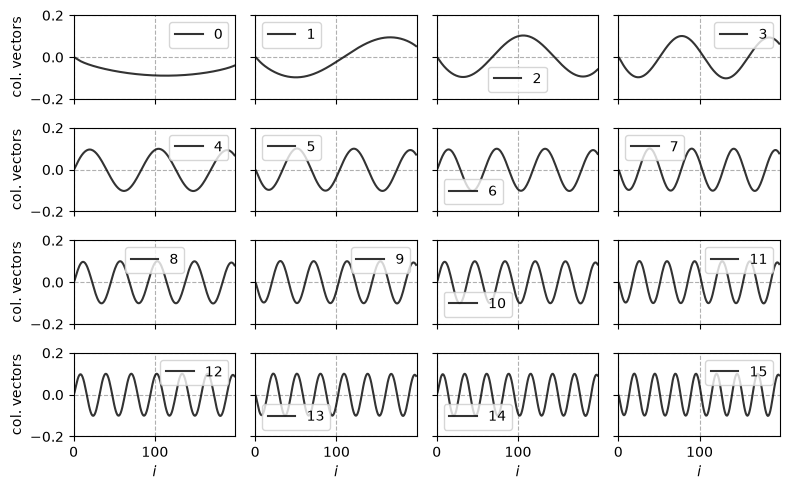

In [9]:
pyregtools.utils.plot_colvecs(u, rows = 4, cols = 4, figsize = (8,5), ylim = (-0.2,0.2))

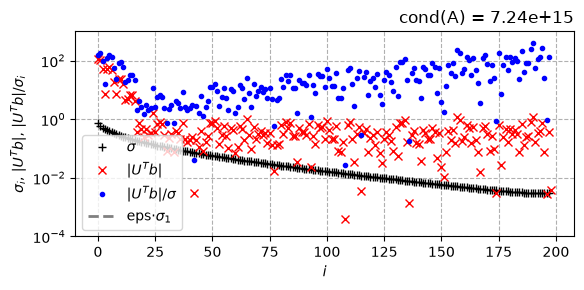

In [10]:
pyregtools.utils.plot_picard(u, s, y, noise_norm = None, figsize = (6,3))
plt.ylim((1e-4, 1e3));

# 6. Tikhonov solution and choosing the optimal $\lambda$

Let's try using a regularized solution based on the SVD of $\mathbb{A}^{\prime}$. Again, the reader is referred back to the [Gravity Survey notebook](gravity_survey.ipynb), in which we studied the technique in detail. The SVD was already computed using `csvd`. Now, we can combine it with the measured data to choose an optimal regularization parameter $\lambda$. We will use the Generalized Cross Validation (GCV) technique in this case. Notice that the GCV function is not well behaved, and if we search for an optimal $\lambda$ over $\sigma_1$ to $\sigma_{N-1}$, we will likely find a very small value of $\lambda$. We can use some good common sense and constrain our search from $\sigma_1$ to $r_{\text{min}\sigma_1}$, with $r_{\text{min}} = 0.001$.

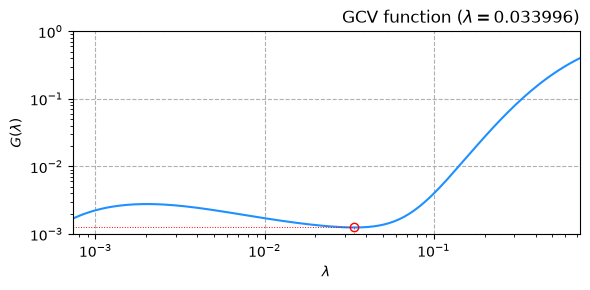

In [11]:
lam_opt = regchoice.gcv_lambda(u, s, y, plotit = True, r_min= 1e-3)

# 7. Comparing different solvers

After finding the optimal value of $\lambda$, we can compare a few solvers. `PyRegTools` provides several solvers in the `regsolvers` module. We will compare:

- Least squares solver;
- Tikhonov solver via SVD;
- Tikhonov solver via analytical formula;
- Ridge solver from scikit-learn;
- Ridge solver from cvxpy;

## 7.1. Least squares solver

This solver computes the solution using numpy least-squares using <a href="https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html" target="_blank">`numpy.linalg.lstsq`</a>. It is equivalent to using the Tikhonov solution with $\lambda = 0$. You will note that the error of such a solution is quite high, since least-squares is prone to overfitting.

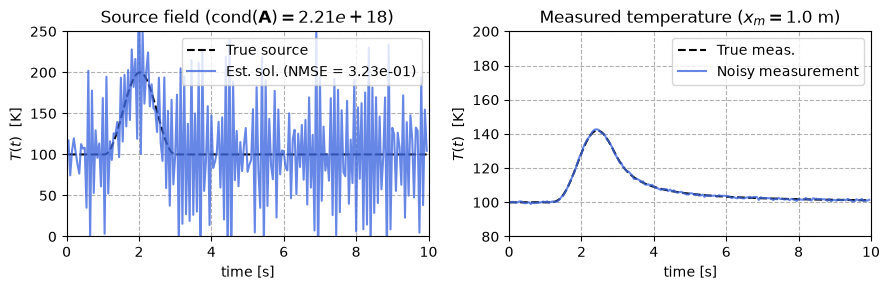

In [12]:
us = regsolvers.least_sq(A, y)
x_ls = us + base_temp
nmse_ls = pyregtools.utils.nmse_fun(x_meas = x_ls, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_ls, nmse = nmse_ls)

## 7.2. Tikhonov SVD solver

This solver is based on the SVD of the sensing matrix, with the solution given by

\begin{equation}        
    \mathbf{x}_{\lambda} = \textbf{V}(\boldsymbol{\Sigma}^{2}+\lambda^2\textbf{I})^{-1}\boldsymbol{\Sigma}\textbf{U}^H \textbf{b}.
\tag{18}
\end{equation} 

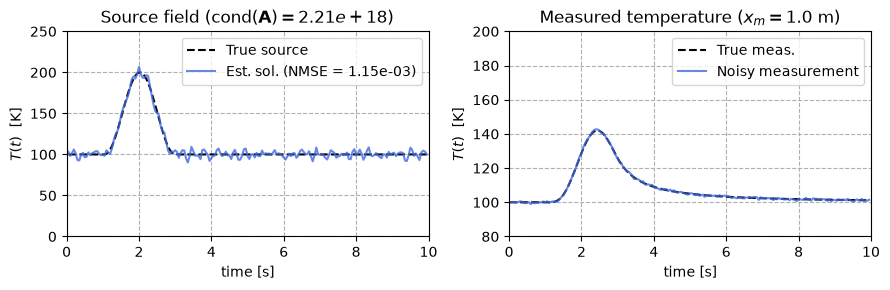

In [13]:
us = regsolvers.tikhonov(u, s, v, y, lam_opt)
x_tik = us + base_temp
nmse_tik = pyregtools.utils.nmse_fun(x_meas = x_tik, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_tik, nmse = nmse_tik)

## 7.3. Tikhonov analytical solver

This solver is based on the SVD of the sensing matrix, with the solution given by

\begin{equation}        
    \mathbf{x}_{\lambda} = \textbf{A}^H(\textbf{A}\textbf{A}^H+\lambda^2\textbf{I})^{-1}\textbf{b}.
\tag{19}
\end{equation} 

For this particular problem, you will notice that the SVD and analytical solvers return the same regularized solution. For problems with more equations than unknowns, the results may change, since the matrix $\textbf{A} \in \mathbb{C}^{M \times L}$ and the matrix $\textbf{A}\textbf{A}^H \in \mathbb{C}^{M \times M}$ might change the problem numerically.  

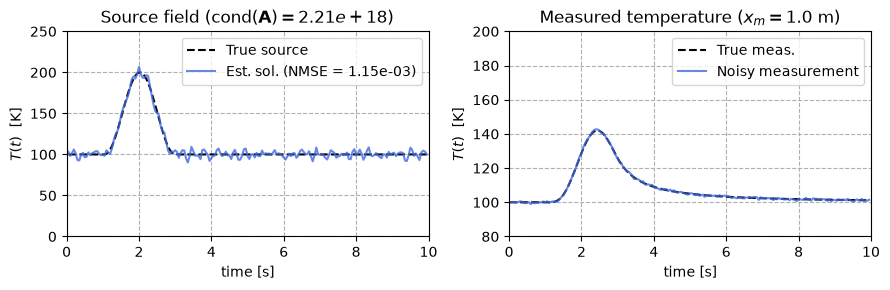

In [14]:
us = regsolvers.tikhonov_analytic(A, y, lam_opt)
x_tik_a = us + base_temp
nmse_tik_a = pyregtools.utils.nmse_fun(x_meas = x_tik_a, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_tik_a, nmse = nmse_tik_a)

## 7.4. Ridge regression via scikit-learn

This solver computes the solution using scikit-learn Ridge regression (another name for the Tikhonov solution) using <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html" target="_blank">`sklearn.linear_model.Ridge`</a>. Note that in scikit-learn Ridge regression notation, the regularization parameter is equivalent to $\lambda^2$.

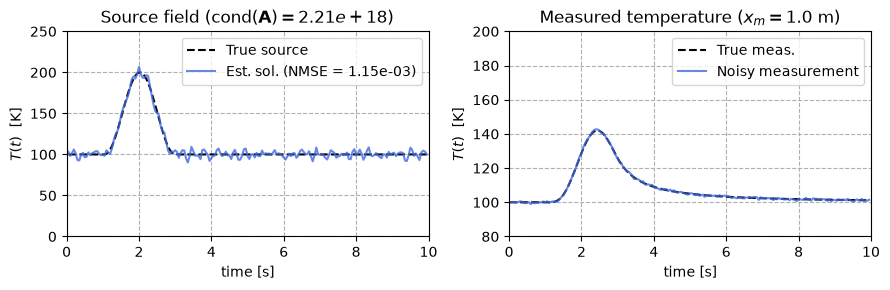

In [15]:
us = regsolvers.sklearn_ridge(A, y, lam_opt**2)
x_tik_sk = us + base_temp
nmse_tik_sk = pyregtools.utils.nmse_fun(x_meas = x_tik_sk, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_tik_sk, nmse = nmse_tik_sk)

## 7.5. Ridge regression from cvxpy

This solver computes the solution using Ridge regression (another name for the Tikhonov solution) using <a href="https://www.cvxpy.org/" target="_blank">`cvxpy`</a>. Note that this solver can be used with real or complex matrices or data. It also provides a way to run a Lasso regression instead of a Ridge regression. We will explore Lasso regression in another notebook (sparsity is not relevant for this problem).

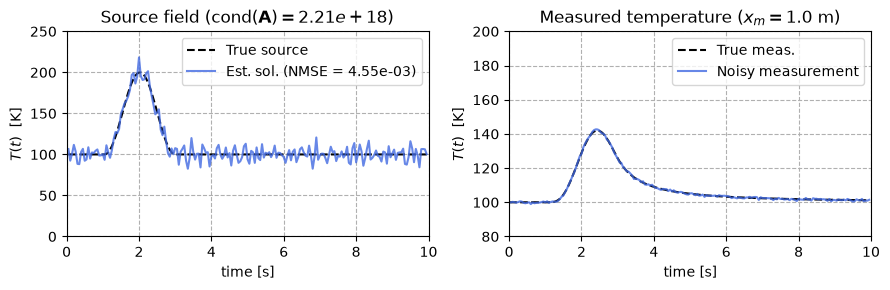

In [16]:
us = regsolvers.cvx_reg(A, y, lam_opt, is_lasso = False, is_complex = False)
x_tik_cvx = us + base_temp
nmse_tik_cvx = pyregtools.utils.nmse_fun(x_meas = x_tik_cvx, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_tik_cvx, nmse = nmse_tik_cvx)

### Comparing solvers so far

Note that the solutions of all solvers are similar in this case, provided that some care is taken with scikit-learn Ridge Regression. The CVX solver performed slightly worse, but this can be case-specific.

Relative difference between SVD Tikhonov and CVX: 3.75e-02


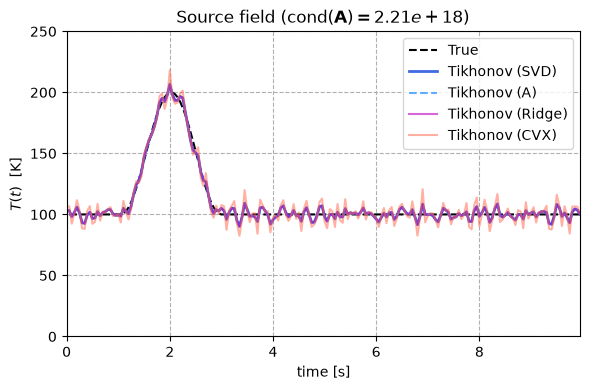

In [17]:
print("Relative difference between SVD Tikhonov and CVX: {:.2e}".format(np.linalg.norm(x_tik - x_tik_cvx) / np.linalg.norm(x_tik)))

plt.figure(figsize = (6,4))
plt.plot(problem.time[1:], problem.x_true, '--k', label = 'True')
plt.plot(problem.time[1:], x_tik, color = 'royalblue', label = 'Tikhonov (SVD)', linewidth = 2)
plt.plot(problem.time[1:], x_tik_a, '--', color = 'dodgerblue', label = 'Tikhonov (A)', alpha = 0.7)
plt.plot(problem.time[1:], x_tik_sk, '-', color = 'm', label = 'Tikhonov (Ridge)', alpha = 0.6)
plt.plot(problem.time[1:], x_tik_cvx, '-', color = 'tomato', label = 'Tikhonov (CVX)', alpha = 0.5)
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((0, problem.time[-1]))
plt.ylim((0, 250))
plt.xlabel(r'time [s]')
plt.ylabel(r'$T(t)$  [K]')
plt.title(r'Source field (cond($\mathbf{{A}}) = {:.2e}$)'.format(np.linalg.cond(problem.A)))
plt.tight_layout()

# 8. Iterative solvers

In the [Image deblurring notebook](image_deblurring.ipynb), we studied some iterative solvers, including the Landweber stationary solver (`iterativesolvers.landweber`) and the Conjugate Gradient Least Squares solver (CGLS - `iterativesolvers.cgls`). Please refer to the mentioned notebook for more theory. For this notebook, we introduce the Landweber-Cimmino method (`iterativesolvers.landweber_cimmino`) and compare it to the CGLS.

## 8.1. Landweber-Cimmino Method

The Landweber-Cimmino method is another classic iterative solver that exhibits **semiconvergence**. One form of this method can be written as

\begin{equation}
\mathbf{x}^{[k+1]} = \mathbf{x}^{[k]} + \omega\mathbf{A}^{H}\mathbf{D} \left(\mathbf{b}-\mathbf{A}\mathbf{x}^{[k]}\right),
\tag {20}
\end{equation}

where $\mathbf{D}=\operatorname{diag}(d_i)$ is a diagonal matrix whose elements depend on the rows of $\mathbf{A}$.

Denoting the $i$-th row of $\mathbf{A}$ by $\mathbf{a}_i^H$, we have

\begin{equation}
d_i =
\begin{cases}
\dfrac{1}{M\|\mathbf{a}_i\|_2^2},
& \mathbf{a}_i \neq \mathbf{0},\\ 
0,
& \mathbf{a}_i = \mathbf{0},
\end{cases}
\tag{21}
\end{equation}

where $M$ is the number of rows of $\mathbf{A}$.

Compared to Landweber’s method, Cimmino’s method therefore introduces a weighting of the residual via the matrix $\mathbf{D}$. Each component of the residual is weighted according to the norm of the corresponding row of $\mathbf{A}$ before applying the adjoint operator.

The normalization introduced by $\mathbf{D}$ also simplifies the choice of the
relaxation parameter. With the above definition, one can use

\begin{equation}
0 < \omega < 2/\left\|\mathbf{D}^{1/2}\mathbf{A}\right\|_2^2.
\tag{22}
\end{equation}

As in the Landweber method, $\omega$ controls the magnitude of the correction made at each iteration. Values close to the upper bound can accelerate convergence, but they can also produce less smooth behavior. The row normalization makes the iterations less sensitive to differences in the magnitudes of the equations. However, it also changes how the residual components are weighted, so the method need not approach the same least-squares solution as unweighted Landweber when the data are inconsistent.

Let's compute solutions as the iterations proceed and store solution and residual norms. 

In [18]:
row_norms = np.linalg.norm(A, axis=1)
D = np.zeros(A.shape[0])
D[row_norms > 0] = 1.0 / (A.shape[0] * row_norms[row_norms > 0]**2)
omega = 0.5 * 2 / np.linalg.norm(np.sqrt(D)[:, None] * A, ord=2)**2

In [19]:
num_iterations = 400
x_est_h, sol_norms, res_norms = iterativesolvers.landweber_cimmino(A, y, omega = omega, x0 = None, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (199, 400)


We can also compare the estimated solutions to the true one and compute the Normalized Mean Square Error (NMSE). Then, we can plot the error history across the course of the iterations. For now, we will choose the one solution with the lowest NMSE. We can do that for demonstration's sake, but in reality we will not have access to the true temperature history.

You will note that the `landweber_cimmino` solver converges slowly. Running a few iterations might not show the semiconvergence behavior. If that is the case, the last iteration will tend to have the lowest NMSE. In this case, running 400 iterations captures semiconvergence (i.e., the NMSE first decreases, then increases).

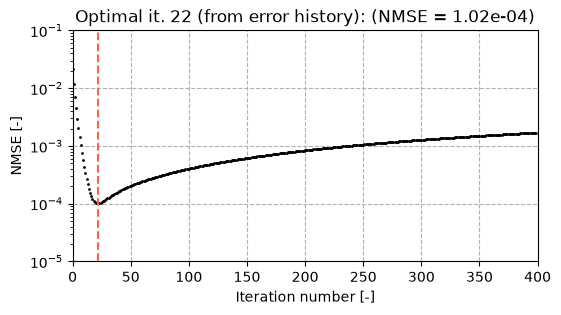

In [20]:
error_hist = pyregtools.utils.nmse_fun(x_est_h+base_temp, problem.x_true[:, None], axis=0)
k_opt = np.argmin(error_hist)
plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, 'ok', markersize = 1)
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.2e})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
plt.xlabel("Iteration number [-]")
plt.ylabel("NMSE [-]")
plt.ylim((1e-5, 1e-1))
plt.xlim((0, x_est_h.shape[1]))
plt.show()

### Choosing the best solution

For this solver, it is difficult to use a criterion such as the L-curve. Then, you can test:

- choose the last iteration as the valid solution
- choose `k_opt` from the error history (which is not completely agnostic, but serves the purpose of demonstration).

The reader can also play with the hyperparameter $\omega$ to check the behavior.

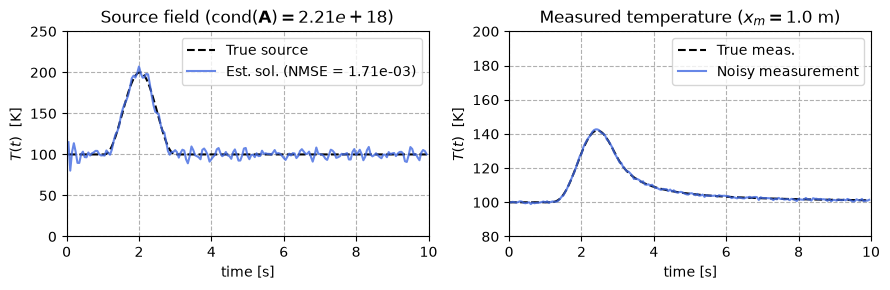

In [21]:
x_lc = x_est_h[:,-1] + base_temp
nmse_lc = pyregtools.utils.nmse_fun(x_meas = x_lc, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_lc, nmse = nmse_lc)

## 8.2 CGLS

Like Landweber-Cimmino, CGLS exhibits **semiconvergence** when applied to ill-posed problems. The first iterations recover the most relevant components of the solution, while later iterations may amplify the measurement noise.

Therefore, **the number of iterations acts as a regularization parameter**. Stopping the algorithm at an appropriate iteration can produce a better reconstruction than allowing it to converge fully.

An important practical advantage is that CGLS does not require a relaxation parameter, such as $\omega$, as in the Landweber-Cimmino method. The step sizes are computed automatically during the iterations.

We can now apply CGLS to the problem at hand. You will note that the CGLS solver converges much faster than the Landweber-Cimmino solver.

In [22]:
num_iterations = 50
x_est_h, sol_norms, res_norms = iterativesolvers.cgls(A, y, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (199, 50)


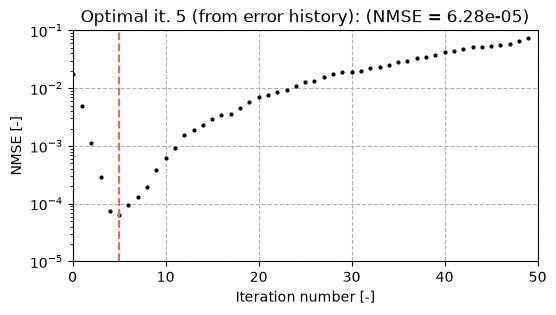

In [23]:
error_hist = pyregtools.utils.nmse_fun(x_est_h+base_temp, problem.x_true[:, None], axis=0)
k_opt = np.argmin(error_hist)
plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, 'ok', markersize = 2)
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.2e})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
plt.xlabel("Iteration number [-]")
plt.ylabel("NMSE [-]")
plt.ylim((1e-5, 1e-1))
plt.xlim((0, x_est_h.shape[1]))
plt.show()

### Choosing the Number of Iterations Using the L-Curve

In iterative regularization methods, the number of iterations $k$ acts as a regularization parameter. One way to select this parameter is through the **L-curve**, constructed from the residual and solution norms at each iteration. To identify this corner automatically, we use the `lcurve_discrete` function from `PyRegTools`, based on the **triangle method** proposed by Castellanos et al. (2002). The reader is advised to read the [Image deblurring notebook](image_deblurring.ipynb) for a more detailed discussion on the method.

The `lcurve_discrete` function returns the index of the selected solution in the original iteration history, allowing us to retrieve the corresponding regularized solution directly.

Note that not all iterative methods produce a well-defined L-shaped curve. In such cases, automatic corner detection may not provide a reliable stopping criterion.

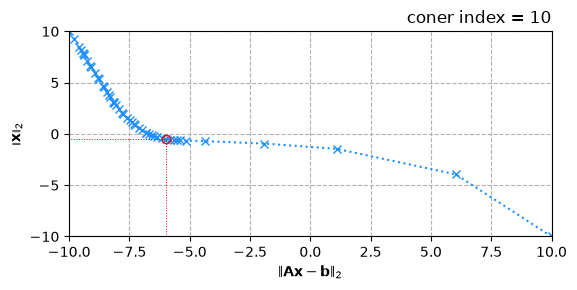

In [24]:
k_l = regchoice.lcurve_discrete(res_norms, sol_norms, plotit=True)

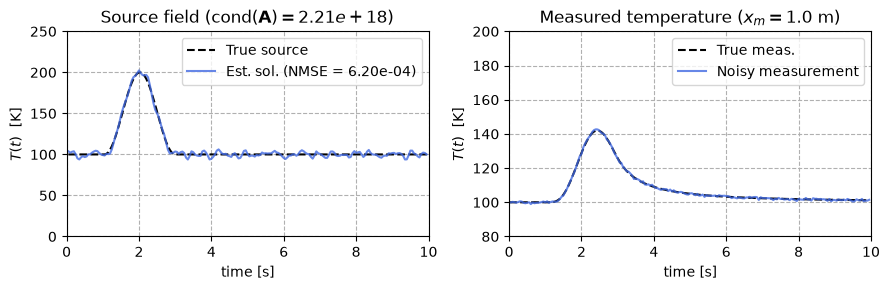

In [25]:
x_cgls = x_est_h[:,k_l] + base_temp
nmse_tik_cgls = pyregtools.utils.nmse_fun(x_meas = x_cgls, x_ref = problem.x_true)
plot_measurement(problem, x_sol = x_cgls, nmse = nmse_tik_cgls)

### Comparing solvers

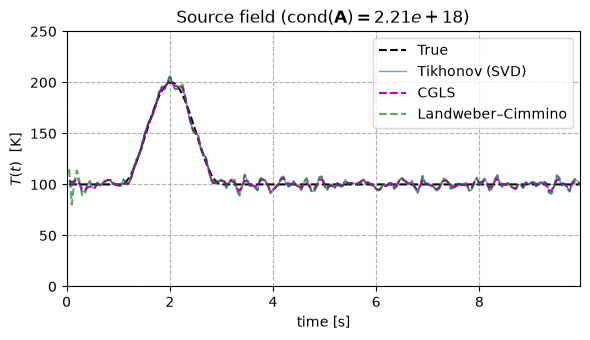

In [26]:
plt.figure(figsize = (6,3.5))
plt.plot(problem.time[1:], problem.x_true, '--k', label = 'True')
plt.plot(problem.time[1:], x_tik, color = 'royalblue', label = 'Tikhonov (SVD)', linewidth = 1, alpha = 0.7)
plt.plot(problem.time[1:], x_cgls, '--', color = 'm', label = 'CGLS', alpha = 1)
plt.plot(problem.time[1:], x_lc, '--', color = 'darkgreen', label = 'Landweber–Cimmino', alpha = 0.6)
plt.legend()
plt.grid(linestyle = '--')
plt.xlim((0, problem.time[-1]))
plt.ylim((0, 250))
plt.xlabel(r'time [s]')
plt.ylabel(r'$T(t)$  [K]')
plt.title(r'Source field (cond($\mathbf{{A}}) = {:.2e}$)'.format(np.linalg.cond(problem.A)))
plt.tight_layout()

# 9. Concluding Remarks

This notebook explored an inverse heat diffusion problem, in which the boundary-temperature history is estimated from measurements taken at a distance from the source. We compared several implementations of Tikhonov regularization and introduced the Landweber–Cimmino iterative method. The results illustrate how the smoothing nature of heat diffusion makes the inverse problem ill-conditioned, why regularization is necessary, and how different solvers can provide comparable reconstructions despite their distinct numerical approaches. We also observed that iterative methods require an appropriate stopping criterion to avoid amplifying measurement noise.